WINE QUALITY PREDICTION

1. INSTALL DEPENDENCIES

In [1]:
!pip -q install "kagglehub[pandas-datasets]" pandas numpy matplotlib seaborn scikit-learn joblib

2. IMPORTS

In [24]:
import os
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
import joblib

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

3. LOAD THE DATASET DIRECTLY FROM KAGGLE

In [25]:
dataset_handle = "uciml/red-wine-quality-cortez-et-al-2009"

dataset_path = kagglehub.dataset_download(dataset_handle)

csv_files = glob.glob(
    os.path.join(dataset_path, "**", "*.csv"),
    recursive=True
)

print("CSV files found:", csv_files)

# Find the red wine dataset
red_file = next(
    (f for f in csv_files if "red" in os.path.basename(f).lower()),
    csv_files[0]
)

# Automatically detect whether the file uses commas or semicolons
df = pd.read_csv(red_file, sep=None, engine="python")

# Clean column names
df.columns = df.columns.str.strip().str.replace('"', '', regex=False)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 records:")
print(df.head())

print("\nDataset shape:", df.shape)

Using Colab cache for faster access to the 'red-wine-quality-cortez-et-al-2009' dataset.
CSV files found: ['/kaggle/input/red-wine-quality-cortez-et-al-2009/winequality-red.csv']

Column names:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

First 5 records:
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51   

4. UNDERSTAND THE DATASET

In [26]:
print("\n========== DATASET INFORMATION ==========")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
print(df.describe().T)


========== DATASET INFORMATION ==========
Rows: 1599
Columns: 12

Column names:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

Data types:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   

5. CHECK DATA QUALITY

In [27]:

# STEP 4: Check data quality

# Ensure column names are clean
df.columns = df.columns.str.strip()

# Confirm that the target column exists
if "quality" not in df.columns:
    raise ValueError(
        f"'quality' column not found. Available columns: {df.columns.tolist()}"
    )

print("\n========== DATA QUALITY ==========")
print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Convert columns to numeric
for column in df.columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Remove rows with missing target values
df = df.dropna(subset=["quality"]).copy()

# Fill missing feature values with the median
feature_columns = [c for c in df.columns if c != "quality"]

for column in feature_columns:
    df[column] = df[column].fillna(df[column].median())

print("\nShape after cleaning:", df.shape)
print("\nRemaining missing values:", df.isnull().sum().sum())
print("\nTarget column exists:", "quality" in df.columns)



========== DATA QUALITY ==========

Missing values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Duplicate rows: 240

Shape after cleaning: (1359, 12)

Remaining missing values: 0

Target column exists: True


6. EXPLORATORY DATA ANALYSIS

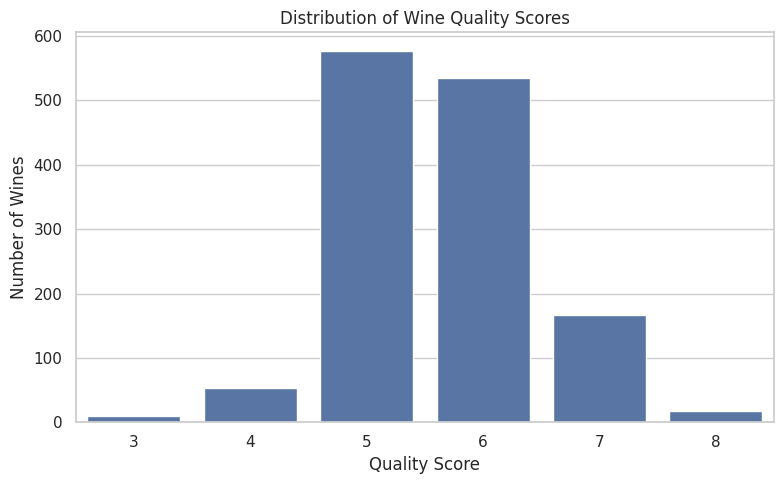

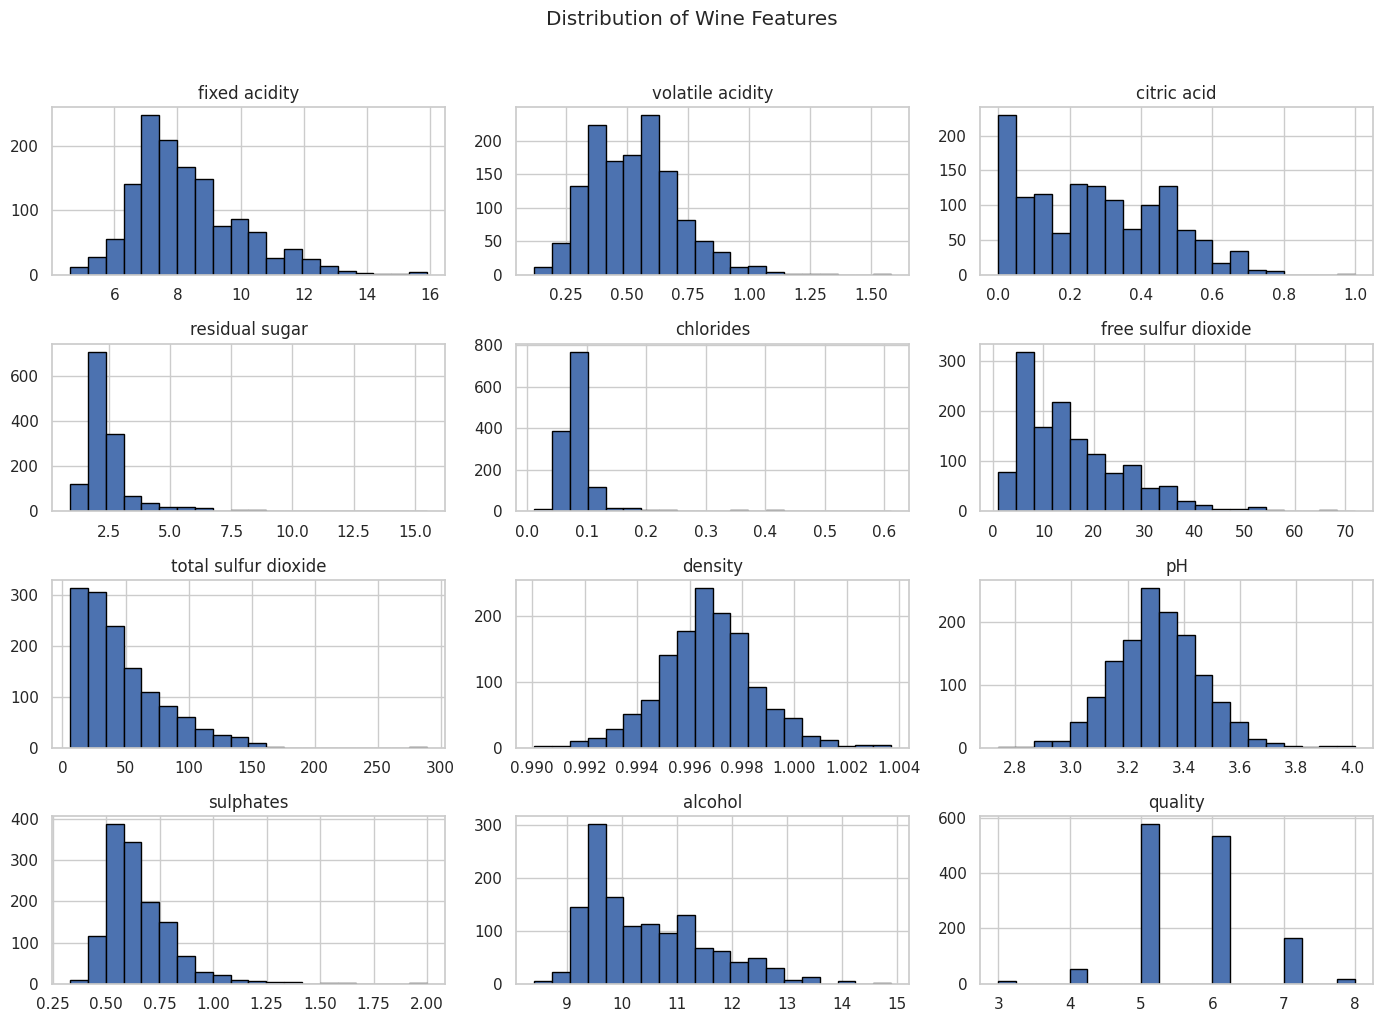

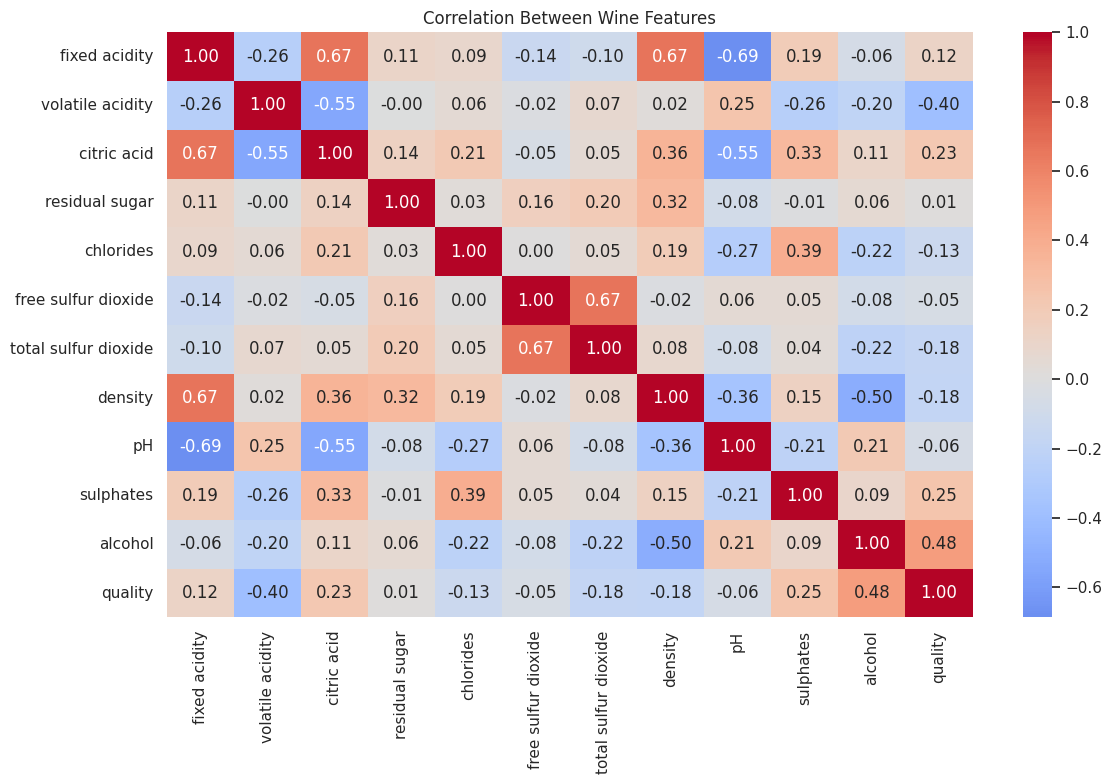


========== FEATURE CORRELATION WITH QUALITY ==========
alcohol                 0.480343
sulphates               0.248835
citric acid             0.228057
fixed acidity           0.119024
residual sugar          0.013640
free sulfur dioxide    -0.050463
pH                     -0.055245
chlorides              -0.130988
total sulfur dioxide   -0.177855
density                -0.184252
volatile acidity       -0.395214
Name: quality, dtype: float64


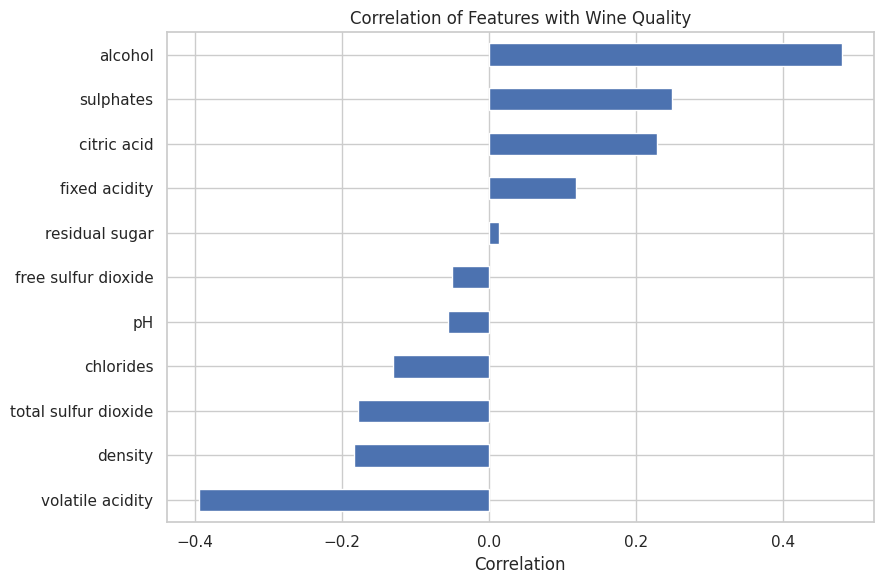

In [28]:
# 5A. Quality score distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="quality")
plt.title("Distribution of Wine Quality Scores")
plt.xlabel("Quality Score")
plt.ylabel("Number of Wines")
plt.tight_layout()
plt.savefig("wine_quality_distribution.png", dpi=300)
plt.show()

# 5B. Histograms of chemical properties
df.hist(figsize=(14, 10), bins=20, edgecolor="black")
plt.suptitle("Distribution of Wine Features", y=1.02)
plt.tight_layout()
plt.savefig("wine_feature_distributions.png", dpi=300)
plt.show()

# 5C. Correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Between Wine Features")
plt.tight_layout()
plt.savefig("wine_correlation_heatmap.png", dpi=300)
plt.show()

# 5D. Correlation with quality
quality_correlations = (
    df.corr(numeric_only=True)["quality"]
    .drop("quality")
    .sort_values(ascending=False)
)

print("\n========== FEATURE CORRELATION WITH QUALITY ==========")
print(quality_correlations)

plt.figure(figsize=(9, 6))
quality_correlations.sort_values().plot(kind="barh")
plt.title("Correlation of Features with Wine Quality")
plt.xlabel("Correlation")
plt.tight_layout()
plt.savefig("wine_quality_correlations.png", dpi=300)
plt.show()


7. CREATE QUALITY CATEGORIES


========== QUALITY CATEGORY COUNTS ==========
quality_category
Average    1112
Good        184
Poor         63
Name: count, dtype: int64


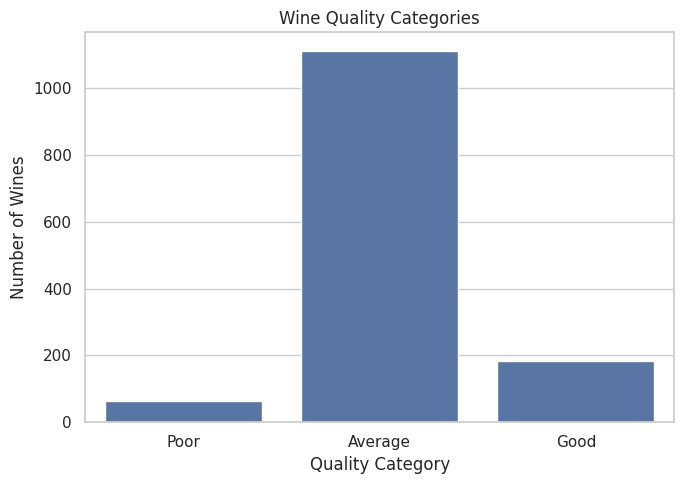

In [29]:
# Poor: quality <= 4
# Average: quality 5 or 6
# Good: quality >= 7

def quality_category(score):
    if score <= 4:
        return "Poor"
    elif score <= 6:
        return "Average"
    else:
        return "Good"

df["quality_category"] = df["quality"].apply(quality_category)

print("\n========== QUALITY CATEGORY COUNTS ==========")
print(df["quality_category"].value_counts())

plt.figure(figsize=(7, 5))
sns.countplot(
    data=df,
    x="quality_category",
    order=["Poor", "Average", "Good"]
)
plt.title("Wine Quality Categories")
plt.xlabel("Quality Category")
plt.ylabel("Number of Wines")
plt.tight_layout()
plt.savefig("wine_quality_categories.png", dpi=300)
plt.show()

8. PREPARE INPUT FEATURES AND TARGET

In [30]:
X = df.drop(columns=["quality", "quality_category"])
y = df["quality_category"]

print("\nInput features:", X.columns.tolist())
print("Target variable: quality_category")

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


Input features: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']
Target variable: quality_category

Training samples: 1087
Testing samples: 272


9. BUILD AND TRAIN MULTIPLE ML MODELS

In [31]:
# Preprocessing is fitted only on the training data through pipelines.

models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", GradientBoostingClassifier(
            random_state=42
        ))
    ])
}

results = []
trained_models = {}

for name, model in models.items():
    print(f"\nTraining {name}...")

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (Macro)": precision_score(
            y_test, predictions,
            average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_test, predictions,
            average="macro", zero_division=0
        ),
        "F1 Score (Macro)": f1_score(
            y_test, predictions,
            average="macro", zero_division=0
        )
    })

    trained_models[name] = model



Training Logistic Regression...

Training Decision Tree...

Training Random Forest...

Training Gradient Boosting...


10. COMPARE MODEL PERFORMANCES


========== MODEL COMPARISON ==========
              Model  Accuracy  Precision (Macro)  Recall (Macro)  F1 Score (Macro)
      Random Forest    0.8419             0.5190          0.4339            0.4514
Logistic Regression    0.5662             0.4442          0.5788            0.4357
  Gradient Boosting    0.8199             0.4564          0.4249            0.4320
      Decision Tree    0.7721             0.4204          0.4129            0.4155


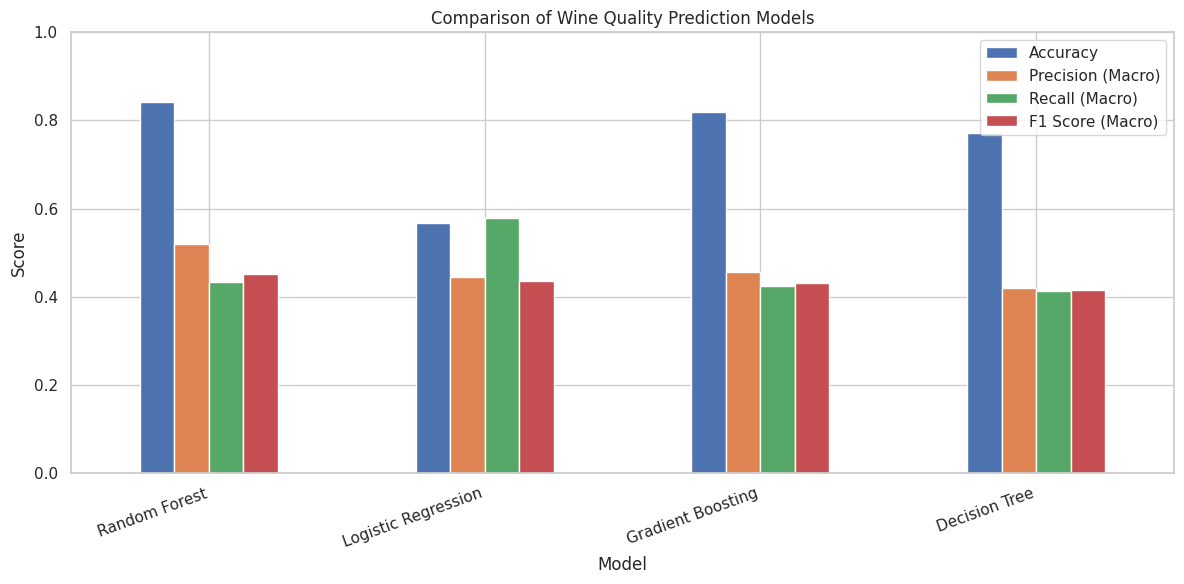

In [32]:
results_df = pd.DataFrame(results).sort_values(
    by="F1 Score (Macro)",
    ascending=False
).reset_index(drop=True)

print("\n========== MODEL COMPARISON ==========")
print(results_df.round(4).to_string(index=False))

results_df.to_csv("wine_model_comparison.csv", index=False)

# Model comparison chart
results_plot = results_df.set_index("Model")[
    ["Accuracy", "Precision (Macro)", "Recall (Macro)", "F1 Score (Macro)"]
]

results_plot.plot(kind="bar", figsize=(12, 6))
plt.title("Comparison of Wine Quality Prediction Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig("wine_model_comparison.png", dpi=300)
plt.show()


11. SELECT THE BEST MODEL USING MACRO F1

In [33]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

y_pred = best_model.predict(X_test)

print("\nBest model:", best_model_name)

print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(
    y_test,
    y_pred,
    labels=["Poor", "Average", "Good"],
    zero_division=0
))


Best model: Random Forest

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

        Poor       0.00      0.00      0.00        13
     Average       0.85      0.98      0.91       222
        Good       0.71      0.32      0.44        37

    accuracy                           0.84       272
   macro avg       0.52      0.43      0.45       272
weighted avg       0.79      0.84      0.80       272



12. CONFUSION MATRIX

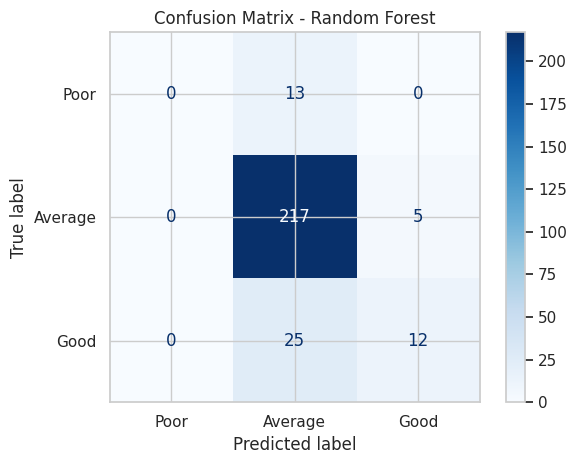

In [34]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Poor", "Average", "Good"]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Poor", "Average", "Good"]
)

display.plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.savefig("wine_confusion_matrix.png", dpi=300)
plt.show()

13. FEATURE IMPORTANCE


========== FEATURE IMPORTANCE ==========
             Feature  Importance
           sulphates    0.153239
    volatile acidity    0.145929
             alcohol    0.135720
total sulfur dioxide    0.084252
                  pH    0.076556
         citric acid    0.076337
           chlorides    0.073668
             density    0.072447
 free sulfur dioxide    0.061975
       fixed acidity    0.060471
      residual sugar    0.059405


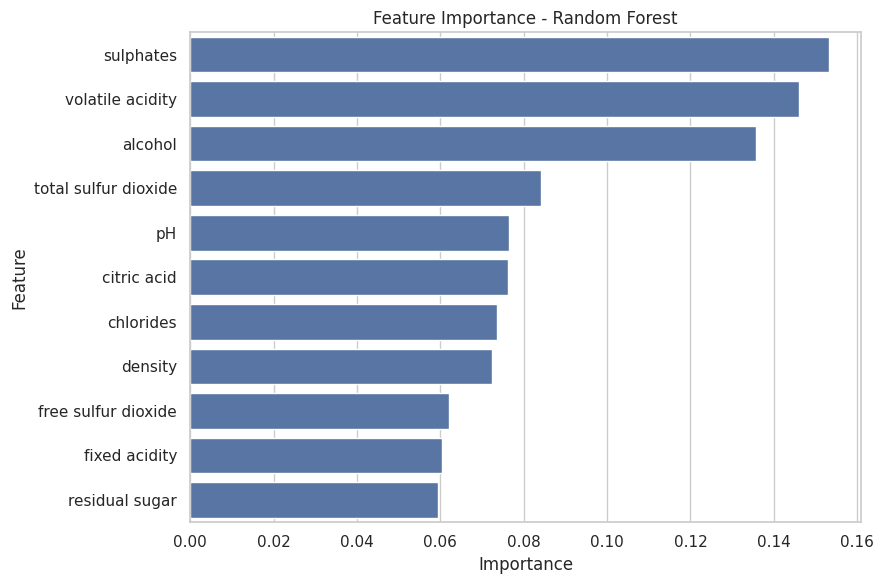

In [35]:
# Tree-based models support feature importance.
# Logistic Regression has coefficients instead.

fitted_estimator = best_model.named_steps["model"]

if hasattr(fitted_estimator, "feature_importances_"):
    importance_values = fitted_estimator.feature_importances_

    importance_df = pd.DataFrame({
        "Feature": X.columns,
        "Importance": importance_values
    }).sort_values("Importance", ascending=False)

    print("\n========== FEATURE IMPORTANCE ==========")
    print(importance_df.to_string(index=False))

    importance_df.to_csv("wine_feature_importance.csv", index=False)

    plt.figure(figsize=(9, 6))
    sns.barplot(
        data=importance_df,
        x="Importance",
        y="Feature"
    )
    plt.title(f"Feature Importance - {best_model_name}")
    plt.tight_layout()
    plt.savefig("wine_feature_importance.png", dpi=300)
    plt.show()

elif hasattr(fitted_estimator, "coef_"):
    coefficients = np.abs(fitted_estimator.coef_).mean(axis=0)

    importance_df = pd.DataFrame({
        "Feature": X.columns,
        "Importance": coefficients
    }).sort_values("Importance", ascending=False)

    print("\nApproximate feature importance from model coefficients:")
    print(importance_df.to_string(index=False))

14. PREDICT QUALITY FOR A SAMPLE WINE

In [36]:
sample_wine = X_test.iloc[[0]]
actual_category = y_test.iloc[0]
predicted_category = best_model.predict(sample_wine)[0]

print("\n========== SAMPLE PREDICTION ==========")
print("Wine measurements:")
print(sample_wine.to_string(index=False))
print("\nActual category:", actual_category)
print("Predicted category:", predicted_category)

# Predict the category for your own measurements:
# Keep the same feature names and order as X.columns.
# Example:
#
# new_wine = pd.DataFrame([{
#     "fixed acidity": 7.4,
#     "volatile acidity": 0.70,
#     "citric acid": 0.00,
#     "residual sugar": 1.9,
#     "chlorides": 0.076,
#     "free sulfur dioxide": 11.0,
#     "total sulfur dioxide": 34.0,
#     "density": 0.9978,
#     "pH": 3.51,
#     "sulphates": 0.56,
#     "alcohol": 9.4
# }])
#
# print(best_model.predict(new_wine))


========== SAMPLE PREDICTION ==========
Wine measurements:
 fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  free sulfur dioxide  total sulfur dioxide  density   pH  sulphates  alcohol
           8.1              0.66          0.7             2.2      0.098                 25.0                 129.0   0.9972 3.08       0.53      9.0

Actual category: Average
Predicted category: Average


15. SAVE THE TRAINED MODEL

In [37]:
joblib.dump(best_model, "best_wine_quality_model.pkl")

print("\nSaved model: best_wine_quality_model.pkl")


Saved model: best_wine_quality_model.pkl


16. SAVE PREDICTIONS FOR REVIEW

In [38]:
prediction_results = X_test.copy()
prediction_results["Actual_Category"] = y_test
prediction_results["Predicted_Category"] = y_pred

prediction_results.to_csv(
    "wine_test_predictions.csv",
    index=False
)

print("Saved test predictions: wine_test_predictions.csv")

Saved test predictions: wine_test_predictions.csv


17. FINAL SUMMARY

In [39]:
print("\n========== FINAL SUMMARY ==========")
print("Original dataset after cleaning:", df.shape)
print("Features used:", X.shape[1])
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Best model:", best_model_name)

best_row = results_df.iloc[0]

print("Accuracy:", round(best_row["Accuracy"], 4))
print("Macro precision:", round(best_row["Precision (Macro)"], 4))
print("Macro recall:", round(best_row["Recall (Macro)"], 4))
print("Macro F1 score:", round(best_row["F1 Score (Macro)"], 4))

print("\nGenerated output files:")
for file in [
    "wine_quality_distribution.png",
    "wine_feature_distributions.png",
    "wine_correlation_heatmap.png",
    "wine_quality_correlations.png",
    "wine_quality_categories.png",
    "wine_model_comparison.csv",
    "wine_model_comparison.png",
    "wine_confusion_matrix.png",
    "wine_feature_importance.csv",
    "wine_feature_importance.png",
    "wine_test_predictions.csv",
    "best_wine_quality_model.pkl"
]:
    if os.path.exists(file):
        print("-", file)

print("\nWine Quality Prediction project completed!")


========== FINAL SUMMARY ==========
Original dataset after cleaning: (1359, 13)
Features used: 11
Training samples: 1087
Testing samples: 272
Best model: Random Forest
Accuracy: 0.8419
Macro precision: 0.519
Macro recall: 0.4339
Macro F1 score: 0.4514

Generated output files:
- wine_quality_distribution.png
- wine_feature_distributions.png
- wine_correlation_heatmap.png
- wine_quality_correlations.png
- wine_quality_categories.png
- wine_model_comparison.csv
- wine_model_comparison.png
- wine_confusion_matrix.png
- wine_feature_importance.csv
- wine_feature_importance.png
- wine_test_predictions.csv
- best_wine_quality_model.pkl

Wine Quality Prediction project completed!
